In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt 

from tqdm import tqdm
from model import ExponentialRepresentation
from utils import plot_ratemaps, rectify, construct_exponential

In [2]:
sA = torch.load("sigma_A.pt", weights_only=True) # Must run fourier_approximation.ipynb first now!
sB = torch.load("sigma_B.pt", weights_only=True)

Gr = torch.load("Gr.pt", weights_only=True)
p0 = torch.load("p0.pt", weights_only=True) 

A, B, R = construct_exponential(sA, sB, Gr)

n_units = A.shape[0] # A.shape = B.shape, so
model = ExponentialRepresentation(A, B)

In [3]:
torch.linalg.norm(p0, dim = -1)

tensor(16.0000, dtype=torch.float32)

In [4]:
ns = 10000 # number of spatial samples
r = (2*torch.rand((ns, 2)).to(torch.float32) - 1) # size of "arena"
v = torch.diff(r, dim = 0) # "velocities"
p_ = model(v, p0) # run


p_ = p_.detach().numpy()
r = r.detach().numpy()

100%|██████████| 9998/9998 [00:10<00:00, 915.09it/s]


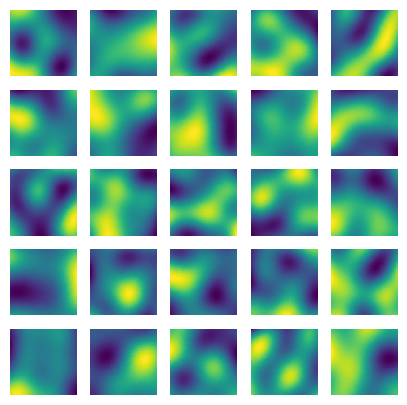

In [5]:
if rect:= False: # rectify or nay
    p = rectify(p_)
else:
    p = p_

ratemaps = plot_ratemaps(r[:-1,0], r[:-1,1], p, 5, figsize=(5,5), bins = 32)

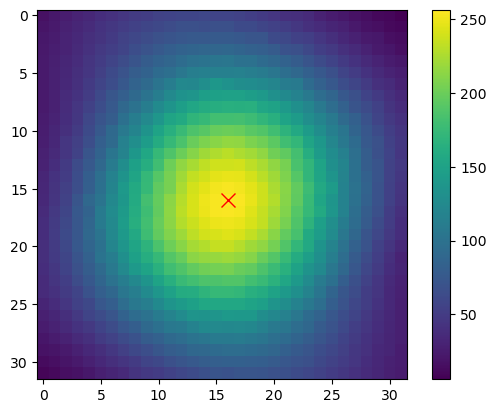

In [6]:
a = 16
diff = (ratemaps[:,a,a,None,None] - ratemaps)**2
prod = np.sum(ratemaps[:,a, a, None,None]*ratemaps, axis = 0)
plt.imshow(prod.T)
plt.plot(a,a, "rx", markersize = 10)
plt.colorbar()

In [7]:
At, Bt, R = construct_exponential(sA, sB, Gr, s = 1.5)

In [8]:
transformed_model = ExponentialRepresentation(At, Bt)

In [9]:
ns = 10000 # number of spatial samples
transformed_p0 = R.T@torch.tensor(np.ones(len(R)).astype(np.float32))
p_transformed = transformed_model(v, transformed_p0) # run

p_transformed = p_transformed.detach().numpy()

100%|██████████| 9998/9998 [00:11<00:00, 898.76it/s]


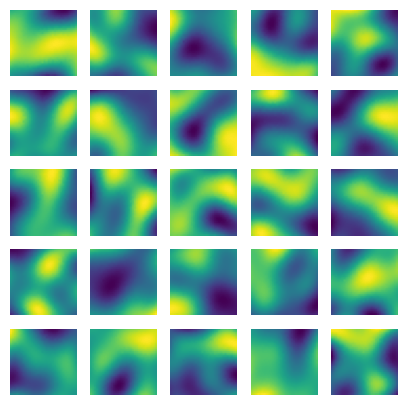

In [10]:
if rect:= False: # rectify or nay
    p_transformed = rectify(p_transformed)
else:
    p_transformed = p_transformed

transformed_ratemaps = plot_ratemaps(r[:-1,0], r[:-1,1], p_transformed, 5, figsize=(5,5), bins = 32)

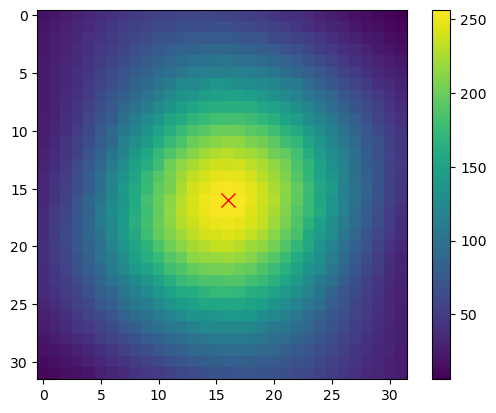

In [11]:
a = 16
transformed_prod = np.sum(transformed_ratemaps[:,a, a, None,None]*transformed_ratemaps, axis = 0)
plt.imshow(transformed_prod.T)
plt.plot(a,a, "rx", markersize = 10)
plt.colorbar()

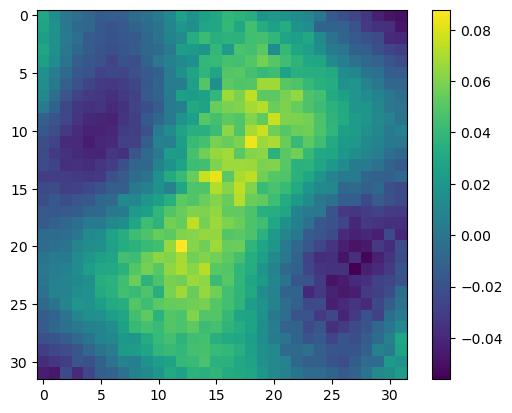

In [12]:
plt.imshow(transformed_prod.T - prod.T)  # difference in correlation structure b/a transform
plt.colorbar()

(array([ 2.,  4.,  9.,  4.,  8., 12., 11., 10., 11.,  6.,  7., 13., 11.,
        16., 12., 12., 10.,  7., 11., 12.,  6.,  9.,  4., 11., 11.,  6.,
         3.,  5.,  8.,  1.,  2.,  2.]),
 array([-0.71186581, -0.6647622 , -0.61765858, -0.57055496, -0.52345135,
        -0.47634773, -0.42924411, -0.3821405 , -0.33503688, -0.28793326,
        -0.24082964, -0.19372603, -0.14662241, -0.09951879, -0.05241518,
        -0.00531156,  0.04179206,  0.08889567,  0.13599929,  0.18310291,
         0.23020652,  0.27731014,  0.32441376,  0.37151738,  0.41862099,
         0.46572461,  0.51282823,  0.55993184,  0.60703546,  0.65413908,
         0.70124269,  0.74834631,  0.79544993]),
 <BarContainer object of 32 artists>)

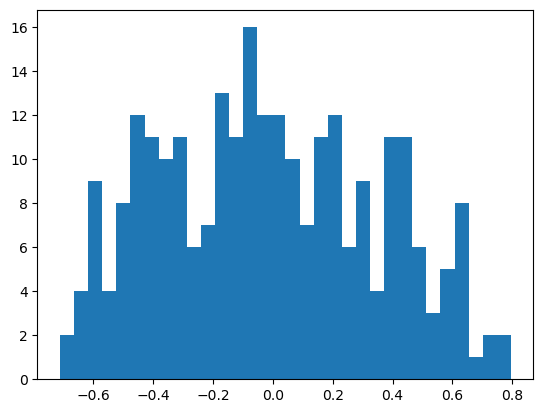

In [13]:
corrs = np.sum(ratemaps*transformed_ratemaps, axis = (1,2))/(np.linalg.norm(ratemaps, axis = (1,2))*np.linalg.norm(transformed_ratemaps, axis = (1,2)))
plt.hist(corrs, bins = 32)